<a href="https://colab.research.google.com/github/inambaig24/TASKS/blob/main/Task1_Iris_Classification_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Multi-Class Benchmark Classification Pipeline (Iris)

**Goal:** Build and compare Logistic Regression and Decision Tree classifiers using the Iris dataset.

This notebook includes:
- Dataset loading and basic inspection
- Exploratory pairplot
- 80/20 train-test split
- Feature scaling with `StandardScaler`
- Logistic Regression and Decision Tree models
- Accuracy, precision, recall, and F1-score
- Confusion-matrix heatmaps
- Decision-boundary visualizations

The Iris dataset is built into scikit-learn, so no separate dataset file is needed.


In [1]:
%pip install pandas matplotlib seaborn scikit-learn

## 2. Import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## 3. Load the Iris dataset

Iris contains 150 flower samples, four numeric features, and three flower classes.

In [3]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="species")

# A combined DataFrame is useful for exploring the data.
df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

print("Dataset shape:", df.shape)
display(df.head())
print("\nClass counts:")
print(df["species"].value_counts())

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Class counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 4. Explore the dataset

First, check data types and missing values. Then create a pairplot to compare the feature distributions for the three flower classes.

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


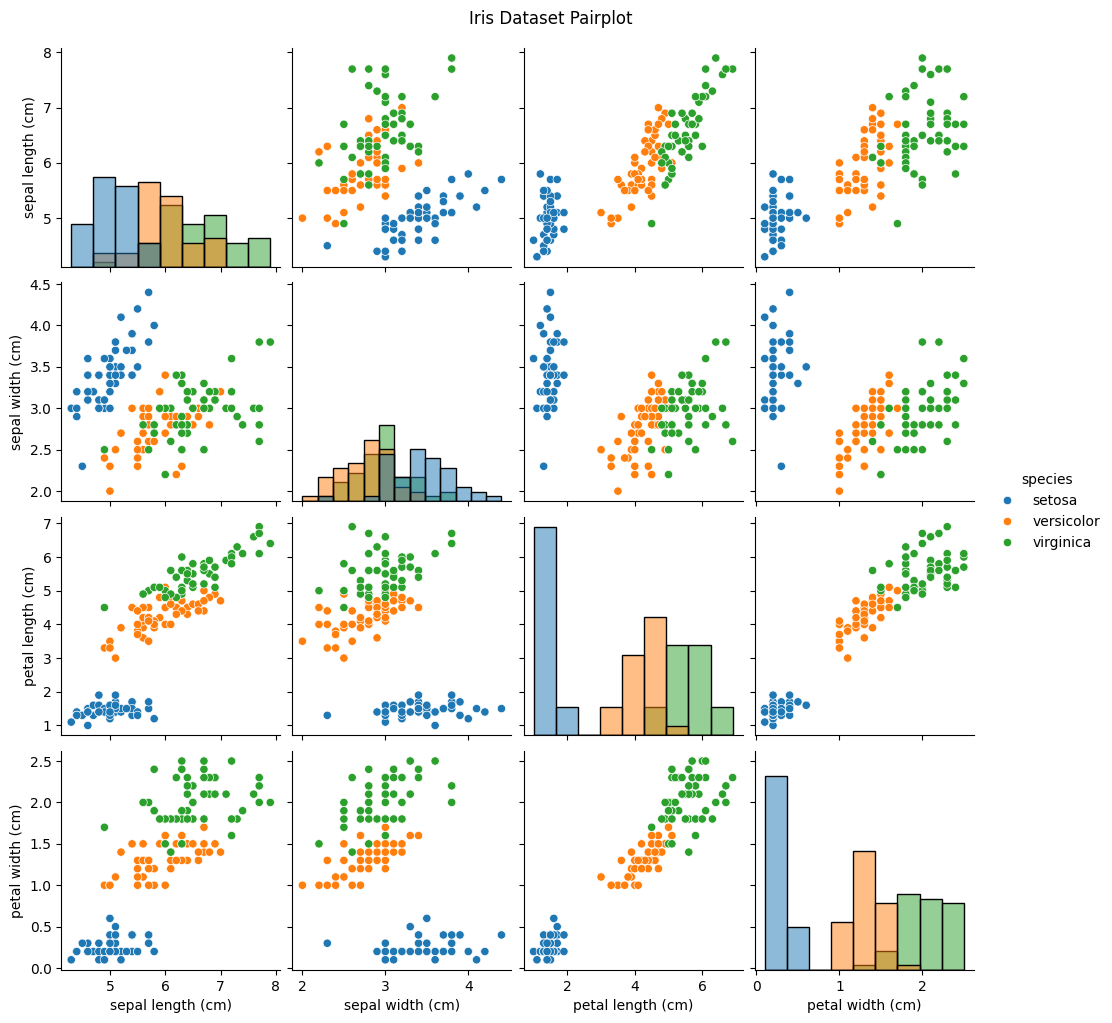

In [4]:
print("Data types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Dataset Pairplot", y=1.02)
plt.show()

## 5. Split the data into training and testing sets

We use **80% for training** and **20% for testing**. `stratify=y` keeps the class proportions similar in both sets. The fixed `random_state` makes the results repeatable.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## 6. Train the two classification models

A pipeline applies `StandardScaler` using only the training data, then trains the classifier. This avoids using test-set information during scaling.

- **Logistic Regression:** a classification algorithm that learns class boundaries.
- **Decision Tree:** learns a sequence of feature-based decisions.

In [6]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(random_state=42)
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.


## 7. Evaluate and compare the models

For this multi-class task, macro-average precision, recall, and F1-score give each class equal weight. Accuracy is the proportion of test examples classified correctly.

In [7]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

print("Detailed classification report: Logistic Regression")
print(classification_report(
    y_test,
    models["Logistic Regression"].predict(X_test),
    target_names=iris.target_names,
    zero_division=0
))

print("Detailed classification report: Decision Tree")
print(classification_report(
    y_test,
    models["Decision Tree"].predict(X_test),
    target_names=iris.target_names,
    zero_division=0
))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


Detailed classification report: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Detailed classification report: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 8. Plot confusion-matrix heatmaps

Rows represent the actual class, and columns represent the predicted class. Large values on the diagonal mean correct predictions; values away from the diagonal mean mistakes.

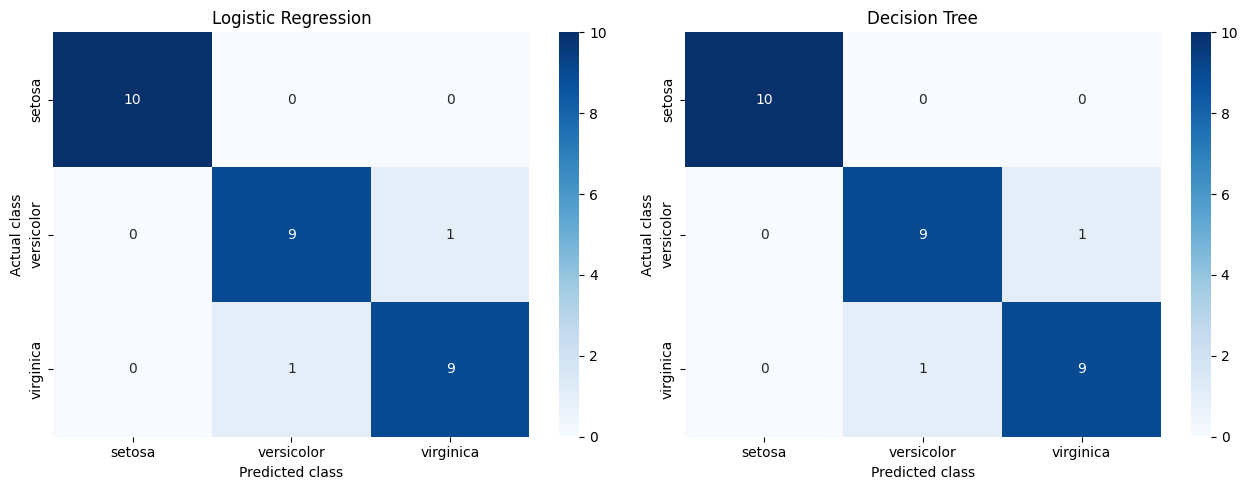

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

## 9. Visualize decision boundaries

A 2D plot can only display two features at a time. For this visualization, we use **petal length** and **petal width**. These visual models are trained only on those two features; the evaluation above uses all four features.

The shaded regions show the class each model predicts across the feature space.

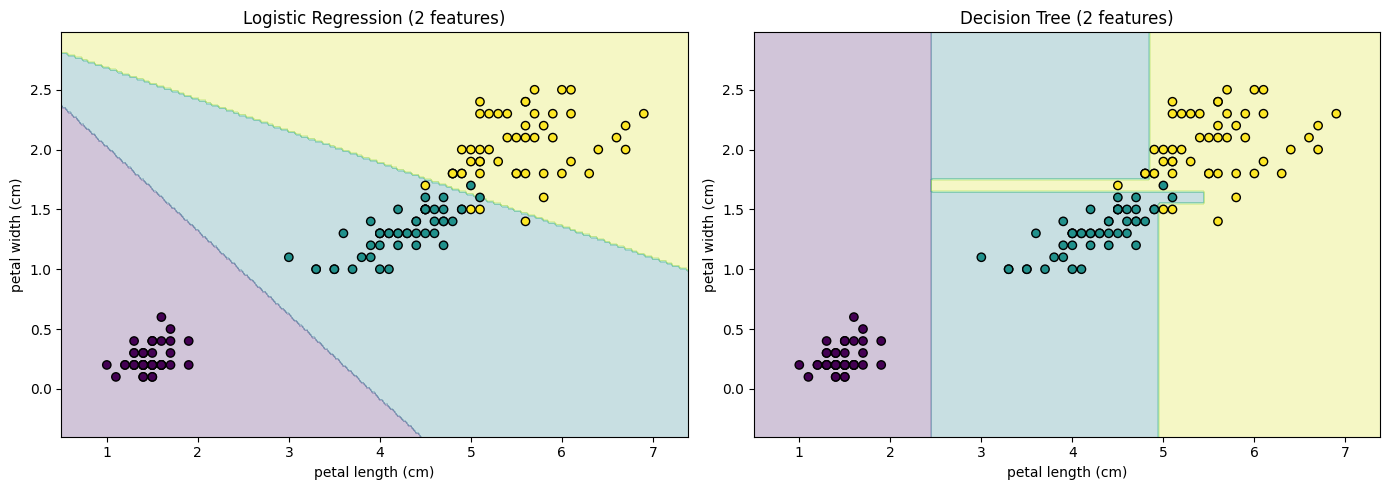

In [9]:
# Select two features so the decision boundary can be shown on a 2D graph.
feature_columns = ["petal length (cm)", "petal width (cm)"]
X_2d = X[feature_columns]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

boundary_models = {
    "Logistic Regression (2 features)": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree (2 features)": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(random_state=42)
    )
}

for model in boundary_models.values():
    model.fit(X_train_2d, y_train_2d)

# Create a grid of points covering the plot.
x_min, x_max = X_2d.iloc[:, 0].min() - 0.5, X_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_2d.iloc[:, 1].min() - 0.5, X_2d.iloc[:, 1].max() + 0.5
xx, yy = __import__("numpy").meshgrid(
    __import__("numpy").arange(x_min, x_max, 0.02),
    __import__("numpy").arange(y_min, y_max, 0.02)
)
grid = pd.DataFrame({
    feature_columns[0]: xx.ravel(),
    feature_columns[1]: yy.ravel()
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, boundary_models.items()):
    predictions = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, predictions, alpha=0.25, cmap="viridis")
    scatter = ax.scatter(
        X_2d.iloc[:, 0],
        X_2d.iloc[:, 1],
        c=y,
        edgecolor="black",
        cmap="viridis"
    )
    ax.set_title(name)
    ax.set_xlabel(feature_columns[0])
    ax.set_ylabel(feature_columns[1])

plt.tight_layout()
plt.show()